# Week 7 Take Home

This week has two parts. Complete **both**.

| Part | Lessons | Project |
|------|---------|---------|
| **A. Cleaning & Visualising Data** | `1-Cleaning & Visualising Data/` | Holiday weather |
| **B. Transforming & Combining Data** | `2-Transforming & Combining Data/` | GDP and life expectancy + your own World Bank project |

Data for both parts comes from the cohort database (schemas `week07` and `week08`). See `Data Access (SQL).md`.

---
# Part A: Cleaning & Visualising Data

### Solve `1-Cleaning & Visualising Data/1.ipynb` Tasks Below

In [ ]:
#Task 1: Select all days that had a northerly wind. 

#all days that had a northerly wind
WindDirection = london['WindDirDegrees']

#rows where direction is >=350 OR <= 10
northerlyDays = london[(WindDirection >= 350) | (WindDirection <= 10)]

print("Days with Northerly wind")
print(northerlyDays)


Days with Northerly wind
           GMT  Max TemperatureC  Mean TemperatureC  Min TemperatureC  \
84  2014-03-26                 9                  6                 2   
90  2014-04-01                19                 13                 7   
100 2014-04-11                16                 12                 9   
110 2014-04-21                19                 12                 5   
174 2014-06-24                24                 19                13   
179 2014-06-29                19                 16                12   
190 2014-07-10                22                 18                14   
208 2014-07-28                23                 19                14   
249 2014-09-07                21                 17                13   
250 2014-09-08                22                 16                10   
335 2014-12-02                 8                  7                 6   
361 2014-12-28                 6                  2                -2   

     Dew PointC  MeanDew 

In [34]:
#Task 2: Select all rows between 1 April 2014 and 11 April 2014

dates = london['GMT']

#specify the start and end dates
start = datetime(2014, 4, 1)
end = datetime(2014, 4, 11)

aprilDays = london[(dates >= start) & (dates <= end)]
print(aprilDays)

           GMT  Max TemperatureC  Mean TemperatureC  Min TemperatureC  \
90  2014-04-01                19                 13                 7   
91  2014-04-02                18                 14                11   
92  2014-04-03                18                 14                11   
93  2014-04-04                15                 12                 9   
94  2014-04-05                14                 10                 6   
95  2014-04-06                16                 14                12   
96  2014-04-07                14                 11                 8   
97  2014-04-08                14                  9                 5   
98  2014-04-09                17                 10                 4   
99  2014-04-10                16                 11                 6   
100 2014-04-11                16                 12                 9   

     Dew PointC  MeanDew PointC  Min DewpointC  Max Humidity  Mean Humidity  \
90           11               9             

In [35]:
#Task 3: 5rows with missing value in the 'Max Gust SpeedKm/h' column.
missingValue = london[london['Max Gust SpeedKm/h'].isnull()]

print("Rows where Max Gust Speed is missing:")
print(missingValue.head())

Rows where Max Gust Speed is missing:
          GMT  Max TemperatureC  Mean TemperatureC  Min TemperatureC  \
4  2014-01-05                12                  7                 1   
10 2014-01-11                 9                  4                 0   
11 2014-01-12                10                  4                -2   
12 2014-01-13                 9                  7                 5   
13 2014-01-14                 7                  4                 1   

    Dew PointC  MeanDew PointC  Min DewpointC  Max Humidity  Mean Humidity  \
4           11               4             -1           100             88   
10           7               3             -1           100             80   
11           9               3             -2           100             91   
12           8               4              3            93             85   
13           5               2              0           100             82   

    Min Humidity  ...  Max VisibilityKm  Mean VisibilityKm  

### Solve `1-Cleaning & Visualising Data/2.ipynb` Tasks Below

<Axes: >

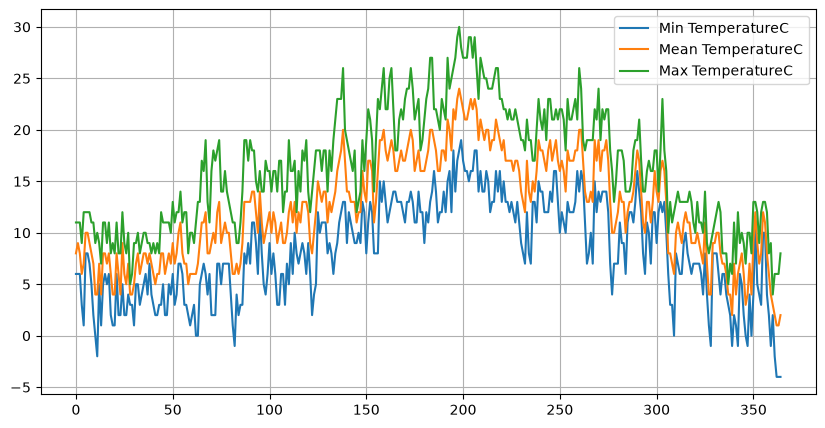

In [36]:
#Task 1: Plot mininmum, mean and maximum temperature during 2014 in London

#Makes sure plots appear in the notebook
%matplotlib inline

london[['Min TemperatureC', 'Mean TemperatureC', 'Max TemperatureC']].plot(grid=True, figsize=(10,5))

<Axes: xlabel='GMT'>

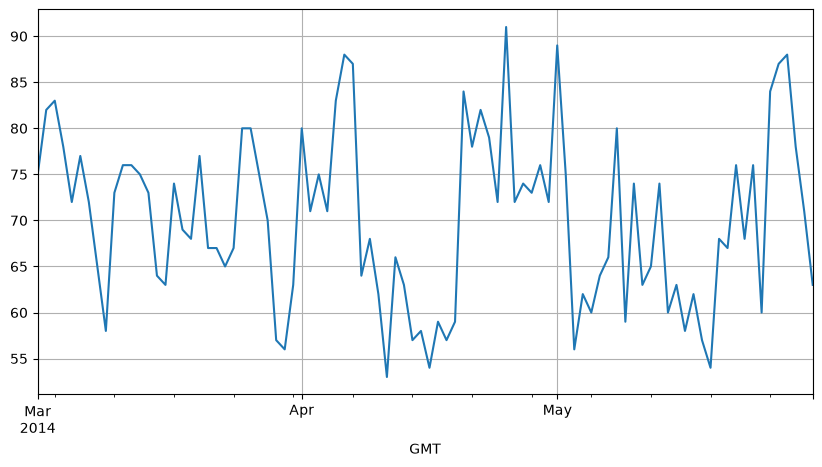

In [38]:
#Task 2: Plot the values of 'Mean Humidity' during spring (full months of march, april and may)

if not isinstance(london.index, pd.DatetimeIndex):
    london.index = london['GMT']
    
#Start and end of spring
springStart = datetime(2014, 3, 1)
springEnd = datetime(2014, 5, 31)

#Select the rows using .loc
springData = london.loc[springStart : springEnd]

#Plotting the values
springData['Mean Humidity'].plot(grid=True, figsize=(10,5))

## Project A: Holiday weather


There is nothing I like better than taking a holiday. In this project I am going to use the historic weather data from the Weather Underground for London to try to predict two good weather weeks to take off as holiday. Of course the weather in the summer of 2025 may be very different to 2020 but it should give some indication of when would be a good time to take a summer break.

## Getting the data

Weather Underground keeps historical weather data collected in many airports around the world. Right-click on the following URL and choose 'Open Link in New Window' (or similar, depending on your browser):

http://www.wunderground.com/history

When the new page opens start typing 'LHR' in the 'Location' input box and when the pop up menu comes up with the option 'LHR, United Kingdom' select it and then click on 'Submit'. 

When the next page opens with London Heathrow data, click on the 'Custom' tab and select the time period From: 1 January 2023 to: 31 December 2023 and then click on 'Get History'. The data for that year should then be displayed further down the page. 

You can copy each month's data directly from the browser to a text editor like Notepad or TextEdit, to obtain a single file with as many months as you wish.


Now load the CSV file into a dataframe making sure that any extra spaces are skipped:

### Step-1 Cleaning the data


In [147]:
#Importing the library

import pandas as pd
from datetime import datetime

import warnings
warnings.simplefilter('ignore', FutureWarning)

In [149]:
#Imported the dataset

heathrowdata = pd.read_csv("hounslow_2023.csv")

In [ ]:
#checking the first 5 rows

print(heathrowdata.head())

         Date  Temperature (C) Max  Temperature (C) Avg  Temperature (C) Min  \
0  2023-01-01                   12                 10.4                    7   
1  2023-01-02                    8                  5.8                    2   
2  2023-01-03                   13                  8.8                    3   
3  2023-01-04                   14                 12.5                   11   
4  2023-01-05                   14                 11.5                   10   

   Dew Point (C) Max  Dew Point (C) Avg  Dew Point (C) Min  Humidity (%) Max  \
0                  9                7.1                  6                93   
1                  6                3.7                  1               100   
2                 11                7.5                  2               100   
3                 11                9.1                  7                94   
4                 10                8.4                  7                94   

   Humidity (%) Avg  Humidity (%) Min 

In [ ]:
#Displaying data info

heathrowdata.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Date                      365 non-null    str    
 1   Temperature (C) Max       365 non-null    int64  
 2   Temperature (C) Avg       365 non-null    float64
 3   Temperature (C) Min       365 non-null    int64  
 4   Dew Point (C) Max         365 non-null    int64  
 5   Dew Point (C) Avg         365 non-null    float64
 6   Dew Point (C) Min         365 non-null    int64  
 7   Humidity (%) Max          365 non-null    int64  
 8   Humidity (%) Avg          365 non-null    float64
 9   Humidity (%) Min          365 non-null    int64  
 10  Wind Speed (km/h) Max     365 non-null    int64  
 11  Wind Speed (km/h) Avg     365 non-null    float64
 12  Wind Speed (km/h) Min     365 non-null    int64  
 13  Pressure (hpa) Max        365 non-null    float64
 14  Pressure (hpa) Avg   

- No null values
- Date column is a str data type, it needs to be changed to datetime

In [158]:
#coverting date str to a datetime

heathrowdata['Date'] = pd.to_datetime(heathrowdata['Date'])

#confirming the conversion
heathrowdata.dtypes

Date                        datetime64[us]
Temperature (C) Max                  int64
Temperature (C) Avg                float64
Temperature (C) Min                  int64
Dew Point (C) Max                    int64
Dew Point (C) Avg                  float64
Dew Point (C) Min                    int64
Humidity (%) Max                     int64
Humidity (%) Avg                   float64
Humidity (%) Min                     int64
Wind Speed (km/h) Max                int64
Wind Speed (km/h) Avg              float64
Wind Speed (km/h) Min                int64
Pressure (hpa) Max                 float64
Pressure (hpa) Avg                 float64
Pressure (hpa) Min                 float64
Precipitation Total (mm)           float64
dtype: object

In [159]:
#Changing the index

heathrowdata.index = heathrowdata['Date']
heathrowdata.head(2)

,Date,Temperature (C) Max,Temperature (C) Avg,Temperature (C) Min,Dew Point (C) Max,Dew Point (C) Avg,Dew Point (C) Min,Humidity (%) Max,Humidity (%) Avg,Humidity (%) Min,Wind Speed (km/h) Max,Wind Speed (km/h) Avg,Wind Speed (km/h) Min,Pressure (hpa) Max,Pressure (hpa) Avg,Pressure (hpa) Min,Precipitation Total (mm)
Date,,,,,,,,,,,,,,,,,
2023-01-01,2023-01-01,12,10.4,7,9,7.1,6,93,80.1,71,31,18.5,4,1007.0,1004.9,1000.0,0.0
2023-01-02,2023-01-02,8,5.8,2,6,3.7,1,100,87.0,70,19,10.4,2,1020.0,1013.9,1006.0,0.0


In [160]:
#deleting the Original date column and checking to make sure it worked

heathrowdata = heathrowdata.drop('Date', axis=1)
heathrowdata.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 365 entries, 2023-01-01 to 2023-12-31
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Temperature (C) Max       365 non-null    int64  
 1   Temperature (C) Avg       365 non-null    float64
 2   Temperature (C) Min       365 non-null    int64  
 3   Dew Point (C) Max         365 non-null    int64  
 4   Dew Point (C) Avg         365 non-null    float64
 5   Dew Point (C) Min         365 non-null    int64  
 6   Humidity (%) Max          365 non-null    int64  
 7   Humidity (%) Avg          365 non-null    float64
 8   Humidity (%) Min          365 non-null    int64  
 9   Wind Speed (km/h) Max     365 non-null    int64  
 10  Wind Speed (km/h) Avg     365 non-null    float64
 11  Wind Speed (km/h) Min     365 non-null    int64  
 12  Pressure (hpa) Max        365 non-null    float64
 13  Pressure (hpa) Avg        365 non-null    float64
 14  Pr

### Step-2 Finding a summer break

According to meteorologists, summer extends for the whole months of June, July, and August in the northern hemisphere and the whole months of December, January, and February in the southern hemisphere. So create a dataframe that holds just those months using the `datetime` index.

In [169]:
#Define summer months for northern hemisphere

northernHemiStart = datetime(2023,6,1)
northernHemiEnd = datetime(2023, 8, 31)

northernSummer = heathrowdata.loc[northernHemiStart : northernHemiEnd]
print("Head of heathrow data")
print(northernSummer.head(2))
print("\nTail of heathrow data")
print(northernSummer.tail(2))


Head of heathrow data
            Temperature (C) Max  Temperature (C) Avg  Temperature (C) Min  \
Date                                                                        
2023-06-01                   19                 13.3                   10   
2023-06-02                   19                 13.8                   10   

            Dew Point (C) Max  Dew Point (C) Avg  Dew Point (C) Min  \
Date                                                                  
2023-06-01                  9                7.7                  6   
2023-06-02                  7                5.7                  4   

            Humidity (%) Max  Humidity (%) Avg  Humidity (%) Min  \
Date                                                               
2023-06-01                87              70.0                49   
2023-06-02                76              59.3                43   

            Wind Speed (km/h) Max  Wind Speed (km/h) Avg  \
Date                                               

Note the precipitate value is 0.0 meaning that there is no measurable rain, snow or hail expected during the forecast period

In [173]:
#To find the 2-weeks prediction of a good holiday

#define summer break (2 weeks)
summer_break = 14

#A new dataframe to hold original stats
northGoodDays = pd.DataFrame(index=northernSummer.index)

#Calulating each good day by using the indicators; average and max temperature values with the precipation for rainy days 
northGoodDays['Avg_Max_Temp'] = northernSummer['Temperature (C) Max'].rolling(window=summer_break).mean()
northGoodDays['Total_Precipitate'] = northernSummer['Precipitation Total (mm)'].rolling(window=summer_break).sum()

print(f'Good days in the Northern Hemisphere: ')
print(northGoodDays)

Good days in the Northern Hemisphere: 
            Avg_Max_Temp  Total_Precipitate
Date                                       
2023-06-01           NaN                NaN
2023-06-02           NaN                NaN
2023-06-03           NaN                NaN
2023-06-04           NaN                NaN
2023-06-05           NaN                NaN
...                  ...                ...
2023-08-27     23.357143                0.0
2023-08-28     23.357143                0.0
2023-08-29     23.142857                0.0
2023-08-30     22.785714                0.0
2023-08-31     22.285714                0.0

[92 rows x 2 columns]


array([[<Axes: xlabel='Date'>],
       [<Axes: xlabel='Date'>]], dtype=object)

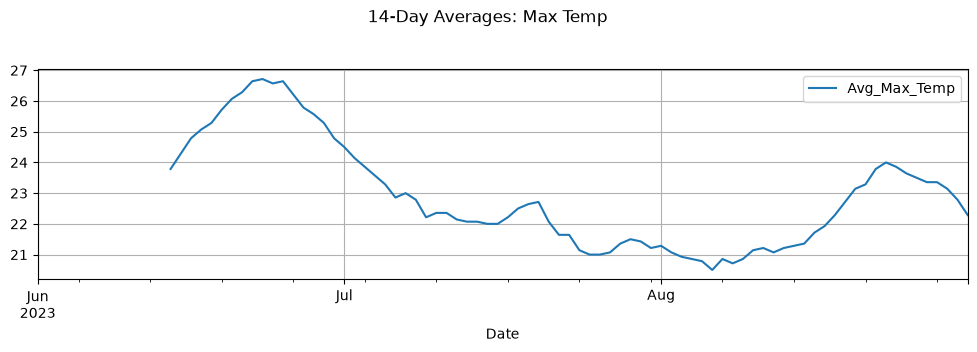

In [174]:
# Plot 1: Max Temperature

northGoodDays[['Avg_Max_Temp']].plot(
    grid=True, 
    figsize=(12, 6),
    title='14-Day Averages: Max Temp',
    subplots=True,
    layout=(2,1) # Arrange them in 2 rows, 1 column
)

<Axes: title={'center': '14-Day Total Precipitation'}, xlabel='Date'>

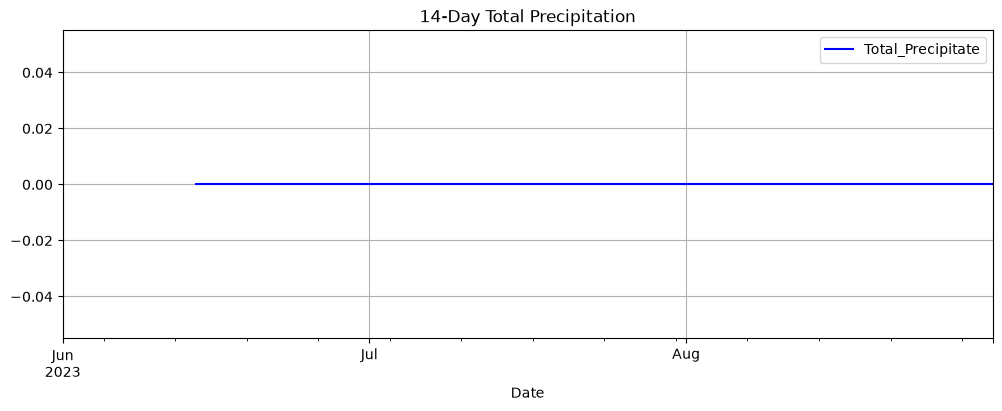

In [175]:
# Plot 2: Precipitation

northGoodDays[['Total_Precipitate']].plot(
    grid=True, 
    figsize=(12, 4),
    title='14-Day Total Precipitation',
    color='blue'
)

In [ ]:
# Dropping null values

bestDays = northGoodDays.dropna()

In [181]:
#Grouping the days into weeks and sorting the best weeks to be at the top
northGoodWeek = northGoodDays['Avg_Max_Temp'].resample('W').count()
bestWeeks = northGoodWeek.sort_values(ascending=False)
print(bestWeeks.head(5))

Date
2023-06-25    7
2023-07-02    7
2023-07-09    7
2023-07-16    7
2023-07-23    7
Name: Avg_Max_Temp, dtype: int64


In [182]:
#Identifying the best 2 weeks for a holiday

topWeeks = bestWeeks.head(2).index
for week in topWeeks:
    start = week - pd.Timedelta(days=6)
    print(f"🌤️ Best Holiday week: {start.date()} → {week.date()}")

🌤️ Best Holiday week: 2023-06-19 → 2023-06-25
🌤️ Best Holiday week: 2023-06-26 → 2023-07-02


The best 2 weeks for a holiday in the northern hemisphere is June 25, 2023 - July 02, 2023

---
# Part B: Transforming & Combining Data

### Provide `2-Transforming & Combining Data/1.ipynb` Tasks Solutions below (Execute them)

In [40]:
#Task 1: Create your population dataframe 'Country name', 'Life expectancy (years)'

import pandas as pd

#create column headings
headings = ['Country name', 'Life expectancy (years)']

#create table data
table = [
  ['China', 75],
  ['Ghana', 71],  
  ['United States', 79],
  ['India', 66],
  ['Mali', 65]
]

#create dataframe
population = pd.DataFrame(columns=headings, data=table)

print(population)

    Country name  Life expectancy (years)
0          China                       75
1          Ghana                       71
2  United States                       79
3          India                       66
4           Mali                       65


In [49]:
#Task 2: Join your population dataframe previous task with gdpVsLife, in four different ways, and note the differences.

#Left Join: Shows all countries from the left table (gdpVsLife)
leftJoin = pd.merge(gdpVsLife, population, on='Country name', how='left')
print('Left Join')
print(leftJoin)

#Right Join: Show all countries from the right table (population)
rightJoin = pd.merge(gdpVsLife, population, on='Country name', how='right')
print('Right Join')
print(rightJoin)

#Inner Join: shows countries present in both tables
innerJoin = pd.merge(gdpVsLife, population, on='Country name', how='inner')
print('Inner Join')
print(innerJoin)

#Outer Join: shows all countries from both tables
outerJoin = pd.merge(gdpVsLife, population, on='Country name', how='outer')
print('Outer Join')
print(outerJoin)

Left Join
     Country name  GDP (£m)  Life expectancy (years)_x  \
0  United Kingdom   1711727                         81   
1   United States  10716029                         79   
2           China   5905202                         75   

   Life expectancy (years)_y  
0                        NaN  
1                       79.0  
2                       75.0  
Right Join
    Country name    GDP (£m)  Life expectancy (years)_x  \
0          China   5905202.0                       75.0   
1          Ghana         NaN                        NaN   
2  United States  10716029.0                       79.0   
3          India         NaN                        NaN   
4           Mali         NaN                        NaN   

   Life expectancy (years)_y  
0                         75  
1                         71  
2                         79  
3                         66  
4                         65  
Inner Join
    Country name  GDP (£m)  Life expectancy (years)_x  \
0  United Sta

In [ ]:
#Task 3: Look through the code you wrote so far, and rewrite it using constants, when appropriate.

#define data
table = [
  ['UK', 2678454886796.7],    # 1st row
  ['USA', 16768100000000.0],  # 2nd row
  ['China', 9240270452047.0], # and so on...
  ['Brazil', 2245673032353.8],
  ['South Africa', 366057913367.1]
]

#create heading
headings = ['Country', 'GDP (US$)']

#create dataframe for gdp
gdp = pd.DataFrame(columns=headings, data=table)

#create heading
headings = ['Country name', 'Life expectancy (years)']
#define data
table = [
  ['China', 75],
  ['Russia', 71],  
  ['United States', 79],
  ['India', 66],
  ['United Kingdom', 81]
]
#create dataframe for life
life = pd.DataFrame(columns=headings, data=table)

#Function to round up values to nearest million
def roundToMillions (value):
    return round(value / 1000000)

#Function to convert usd to gbp
def usdToGBP (usd):
    return usd / 1.564768 # average rate during 2013 

#function to expand values
def expandCountry (name):
    if name == 'UK':
        return 'United Kingdom'
    elif name == 'USA':
        return 'United States'
    else:
        return name

#Applying functions to values
gdp['Country name'] = gdp['Country'].apply(expandCountry)
gdp['GDP (£m)'] = gdp['GDP (US$)'].apply(usdToGBP).apply(roundToMillions)
gdp['GDP (US$)'].apply(roundToMillions).apply(usdToGBP).apply(round)

#Define constants
COUNTRY = 'Country name'
GDP_USD = 'GDP (US$)'
GDP_GBP = 'GDP (£m)'

#creating headings with constants
headings = [COUNTRY, GDP_GBP, GDP_USD]
gdp = gdp[headings]

print(gdp)

     Country name  GDP (£m)     GDP (US$)
0  United Kingdom   1711727  2.678455e+12
1   United States  10716029  1.676810e+13
2           China   5905202  9.240270e+12
3          Brazil   1435148  2.245673e+12
4    South Africa    233937  3.660579e+11


### Provide `2-Transforming & Combining Data/2.ipynb` Tasks Solutions below (Execute them)

In [53]:
#Task 1: Create a data frame with the World Bank's data on population, using the CSV file provided.

#TOTAL POPULATION 2013
POPULATION_INDICATOR = 'SP.POP.TOTL'
populationReset = run_query("SELECT * FROM week08.wb_pop_2013")
populationReset.head()

,country,year,SP.POP.TOTL
0,Arab World,2013,3.770967e+08
1,Caribbean small states,2013,6.975819e+06
2,Central Europe and the Baltics,2013,1.037137e+08
3,East Asia & Pacific (all income levels),2013,2.248867e+09
4,East Asia & Pacific (developing only),2013,2.006073e+09


### Provide `2-Transforming & Combining Data/2.ipynb` Assignment Solutions below (Execute them)

In [ ]:
#Task 2: Clean the population dataframe you created in the previous task.

#Slice out rows with real countries
populationCountries = populationReset[34:]
populationCountries.head()

,country,year,SP.POP.TOTL
34,Afghanistan,2013,30682500.0
35,Albania,2013,2897366.0
36,Algeria,2013,38186135.0
37,American Samoa,2013,55302.0
38,Andorra,2013,75902.0


In [55]:
#Drop empty rows
populationData = populationCountries.dropna()
populationData.head()

,country,year,SP.POP.TOTL
34,Afghanistan,2013,30682500.0
35,Albania,2013,2897366.0
36,Algeria,2013,38186135.0
37,American Samoa,2013,55302.0
38,Andorra,2013,75902.0


In [56]:
#Drop year column

COUNTRY = 'country'
headings = [COUNTRY, POPULATION_INDICATOR]
populationClean = populationData[headings]
populationClean.head()

,country,SP.POP.TOTL
34,Afghanistan,30682500.0
35,Albania,2897366.0
36,Algeria,38186135.0
37,American Samoa,55302.0
38,Andorra,75902.0


In [69]:
#Task 3: Merge gdpVsLifeClean with the population dataframe obtained in the previous exercise.

gdpVsPopAll = pd.merge(gdpVsLifeClean, populationClean, on=COUNTRY, how='inner')
gdpVsPopAll.head()

,country,GDP (£m),Life expectancy (years),SP.POP.TOTL
0,Afghanistan,13075,60,30682500.0
1,Albania,8168,78,2897366.0
2,Algeria,134016,75,38186135.0
3,Angola,88420,52,23448202.0
4,Antigua and Barbuda,767,76,89985.0


In [ ]:
#Round the population value to the nearest million

POP = 'population'
column = gdpVsPopAll[POPULATION_INDICATOR]
gdpVsPopAll[POP] = column.apply(round)
gdpVsPopAll.head()

,country,GDP (£m),Life expectancy (years),SP.POP.TOTL,population
0,Afghanistan,13075,60,30682500.0,30682500
1,Albania,8168,78,2897366.0,2897366
2,Algeria,134016,75,38186135.0,38186135
3,Angola,88420,52,23448202.0,23448202
4,Antigua and Barbuda,767,76,89985.0,89985


In [71]:
# Remove the original population column.

headings = [COUNTRY, GDP,LIFE, POP]
gdpVsPopClean = gdpVsPopAll[headings]
gdpVsPopClean.head()

,country,GDP (£m),Life expectancy (years),population
0,Afghanistan,13075,60,30682500
1,Albania,8168,78,2897366
2,Algeria,134016,75,38186135
3,Angola,88420,52,23448202
4,Antigua and Barbuda,767,76,89985


In [74]:
#Task 4: Calculate the correlation between GDP and population.

from scipy.stats import spearmanr

gdpColumn = gdpVsLifeClean[GDP]
popColumn = gdpVsPopClean[POP]
(correlation, pValue) = spearmanr(gdpColumn, popColumn)
print('The correlation is', correlation)
if pValue < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')

The correlation is 0.708565007995748
It is statistically significant.


<Axes: xlabel='Life expectancy (years)', ylabel='GDP (£m)'>

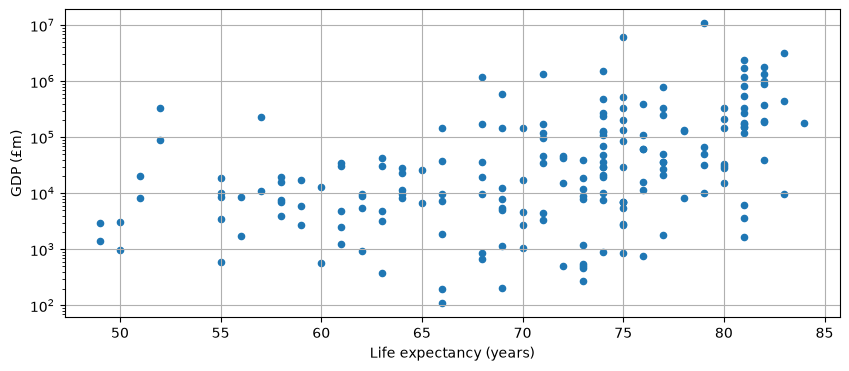

In [77]:
#Task 5: Swap the axes of the scatterplot, i.e. show the GDP in the y axis and the life expectancy in the x axis.

gdpVsLifeClean.plot(x=LIFE, y=GDP, kind='scatter', grid=True, logy=True, figsize = (10, 4))

<Axes: xlabel='GDP (£m)', ylabel='population'>

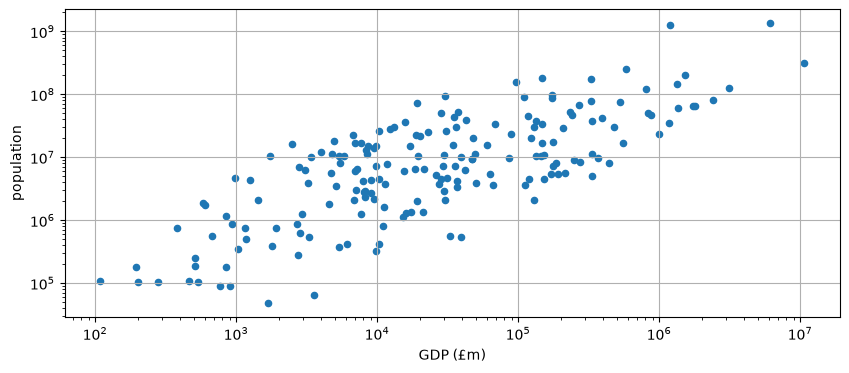

In [78]:
#Display a scatterplot of the GDP and the population.

gdpVsPopClean.plot(x=GDP, y=POP, kind='scatter', grid=True, logx=True, logy= True, figsize = (10, 4))

Assignment

In [79]:
#Assignment 1: To what extent do the ten countries with the highest GDP coincide with the ten countries with the longest life expectancy?

#Sort by GDP
sortedGdp = gdpVsLifeClean.sort_values(by='GDP (£m)',ascending=False)

#create the top 10 countries with highest GDP
sortedGDP = sortedGdp.head(10)[[COUNTRY, 'GDP (£m)']]
sortedGDP

,country,GDP (£m)
177,United States,10715999
35,China,6065182
83,Japan,3143957
62,Germany,2393529
58,France,1795953
176,United Kingdom,1733354
23,Brazil,1528714
81,Italy,1363486
138,Russian Federation,1328647
75,India,1189826


In [80]:
#Sort by life expectancy
sortedLife = gdpVsLifeClean.sort_values(by='Life expectancy (years)',ascending=False)

#create the top 10 countries with longest life expectancy
sortedLIFE = sortedLife.head(10)[[COUNTRY, 'Life expectancy (years)']]
sortedLIFE

,country,Life expectancy (years)
72,"Hong Kong SAR, China",84
74,Iceland,83
162,Switzerland,83
83,Japan,83
99,Luxembourg,82
147,Singapore,82
161,Sweden,82
154,Spain,82
58,France,82
7,Australia,82


In [82]:
#Compare both

coincidence = pd.merge(sortedGDP, sortedLIFE, on=COUNTRY, how='inner')
print('The ten countries with the highest GDP which coincides with the ten countries with the longest life expectancy')
print(coincidence)

The ten countries with the highest GDP which coincides with the ten countries with the longest life expectancy
  country  GDP (£m)  Life expectancy (years)
0   Japan   3143957                       83
1  France   1795953                       82


In [83]:
#Assignment 2: Which are the two countries in the right half of the plot (higher GDP) with life expectancy below 60 years?

#Find the 50th percentile (median) of the GDP
gdpMedian = gdpVsLifeClean['GDP (£m)'].median()

#Filters the right half of the plot and the values where life expectancy < 60
filteredData = gdpVsLifeClean[(gdpVsLifeClean['GDP (£m)'] > gdpMedian) & (gdpVsLifeClean['Life expectancy (years)'] < 60)]

print(filteredData.head(2))

     country  GDP (£m)  Life expectancy (years)
3     Angola     88420                       52
124  Nigeria    329100                       52


In [ ]:
#Assignment 3: What factors could explain their lower life expectancy compared to countries with similar GDP?

#A. Social determinants of health - Income inequality, education & literacy rates, nutrition & food security, housing & environment.
#B. Healthcare system quality & accessibility - access to publicly funded care, quality & infrastructure, healthcare financing
#C. Lifestyle & behavioural factors - substance abuse, obesity, physical activity & diet
#D. Governance & stability - social safety nets, public health policies, political stability & governance.

In [89]:
#Assignment 4: Redo the analysis using the countries’ GDP per capita (i.e. per inhabitant) instead of their total GDP

#Replacing GDP with GDP per Capita

#Create a new column
GDP_PCAP = 'GDP per Capita (£)'

gdpData = gdpVsPopClean['GDP (£m)']

#Calculating total population
totalPopulation = gdpVsPopClean[POP] * 1000000

#Calculating GDP per Capita
gdpVsPopClean[GDP_PCAP] = (gdpData / totalPopulation).round(2)

print(gdpVsPopClean.head())

               country  GDP (£m)  Life expectancy (years)  population  \
0          Afghanistan     13075                       60    30682500   
1              Albania      8168                       78     2897366   
2              Algeria    134016                       75    38186135   
3               Angola     88420                       52    23448202   
4  Antigua and Barbuda       767                       76       89985   

   GDP per Capita (£)  
0                 0.0  
1                 0.0  
2                 0.0  
3                 0.0  
4                 0.0  


In [ ]:
#Check correlation

from scipy.stats import spearmanr

gdpPcap = gdpVsPopClean[GDP_PCAP]
lifeColumn = gdpVsPopClean['Life expectancy (years)']

(correlation, pValue) = spearmanr(gdpPcap,lifeColumn)
print('The Correlation is', correlation)
if pValue < 0.05:
    print("It is statistically significant")
else:
    print("It is not statistically significant")

The Correlation is nan
It is not statistically significant


C:\Users\HP\AppData\Local\Temp\ipykernel_13264\2547302905.py:8: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  (correlation, pValue) = spearmanr(gdpPcap,lifeColumn)


c:\Users\HP\Documents\Projects DataraFlow\.venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:848: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  labels = axis.get_majorticklabels() + axis.get_minorticklabels()


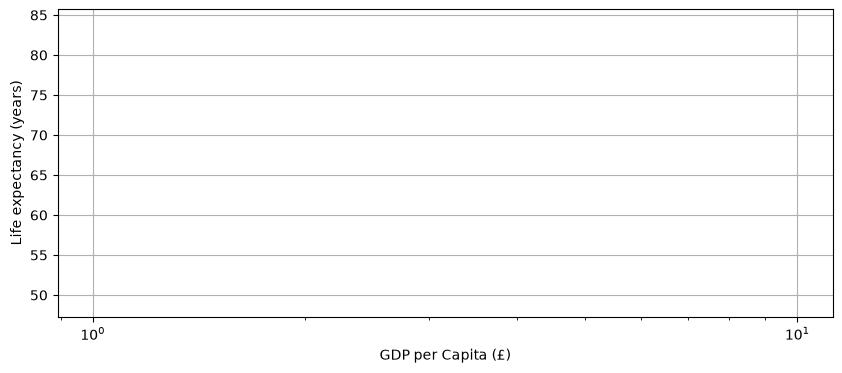

In [ ]:
#Plotting
%matplotlib inline
import matplotlib.pyplot as plt

gdpVsPopClean.plot(x=GDP_PCAP, y='Life expectancy (years)', kind= 'scatter', grid=True, logx=True, figsize=(10,4))
plt.show()

The analysis showed 0.0 values and had a correlation of NaN. No positive values therefore cannot be log-scaled.

This was caused because the population to millions was rounded causing a "divide by zero" error when calculating the GDP per capita.


In [ ]:
#Assignment 5: Redoing the analysis using the indicator provided
GDP_PCAP_INDICATOR = 'NY.GDP.PCAP.PP.CD'

from pandas_datareader.wb import download

YEAR = 2013
gdpPcapWB = download(indicator = GDP_PCAP_INDICATOR, country= 'all', start=YEAR, end=YEAR)
gdpPcapWB.head()

,,NY.GDP.PCAP.PP.CD
country,year,
Africa Eastern and Southern,2013,3373.428766
Africa Western and Central,2013,4867.130763
Arab World,2013,16054.040416
Caribbean small states,2013,20901.494764
Central Europe and the Baltics,2013,23869.112331


In [96]:
#rest index
gdpPcapReset = gdpPcapWB.reset_index()
gdpPcapReset.head()

,country,year,NY.GDP.PCAP.PP.CD
0,Africa Eastern and Southern,2013,3373.428766
1,Africa Western and Central,2013,4867.130763
2,Arab World,2013,16054.040416
3,Caribbean small states,2013,20901.494764
4,Central Europe and the Baltics,2013,23869.112331


In [ ]:
#Slice non-countries
gdpPcapCountries = gdpPcapReset[49:]
gdpPcapCountries.head()

,country,year,NY.GDP.PCAP.PP.CD
49,Afghanistan,2013,2133.241271
50,Albania,2013,10882.042304
51,Algeria,2013,14370.820662
52,American Samoa,2013,NaN
53,Andorra,2013,45609.230724


In [104]:
#drop countries with null values
gdpPcapData = gdpPcapCountries.dropna()
gdpPcapData.head()

,country,year,NY.GDP.PCAP.PP.CD
49,Afghanistan,2013,2133.241271
50,Albania,2013,10882.042304
51,Algeria,2013,14370.820662
53,Andorra,2013,45609.230724
54,Angola,2013,8504.095321


In [105]:
#drop year column
headings = ['country', GDP_PCAP_INDICATOR]
gdpPcapClean = gdpPcapData[headings]
gdpPcapClean.head()

,country,NY.GDP.PCAP.PP.CD
49,Afghanistan,2133.241271
50,Albania,10882.042304
51,Algeria,14370.820662
53,Andorra,45609.230724
54,Angola,8504.095321


In [106]:
lifeClean

,country,SP.DYN.LE00.IN
34,Afghanistan,60.028268
35,Albania,77.537244
36,Algeria,74.568951
39,Angola,51.866171
40,Antigua and Barbuda,75.778659
...,...,...
243,Virgin Islands (U.S.),79.624390
244,West Bank and Gaza,73.203341
245,"Yemen, Rep.",63.583512
246,Zambia,59.237366


In [107]:
#Merge them together

gdpPcapVsLife = pd.merge(gdpPcapClean, lifeClean, on='country', how='inner')
gdpPcapVsLife.head()

,country,NY.GDP.PCAP.PP.CD,SP.DYN.LE00.IN
0,Afghanistan,2133.241271,60.028268
1,Albania,10882.042304,77.537244
2,Algeria,14370.820662,74.568951
3,Angola,8504.095321,51.866171
4,Antigua and Barbuda,21760.523286,75.778659


In [ ]:
#Rename column headings
gdpPcapVsLife.rename(columns={'NY.GDP.PCAP.PP.CD': 'GDP per Capita (£)', 'SP.DYN.LE00.IN': 'Life expectancy (years)'}, inplace=True)
gdpPcapVsLife.head()

,country,GDP per Capita (£),Life expectancy (years)
0,Afghanistan,2133.241271,60.028268
1,Albania,10882.042304,77.537244
2,Algeria,14370.820662,74.568951
3,Angola,8504.095321,51.866171
4,Antigua and Barbuda,21760.523286,75.778659


In [109]:
#Apply round function

GDP_PCAP = 'GDP per Capita (£)'
LIFE = 'Life expectancy (years)'

gdpPcapVsLife[LIFE] = gdpPcapVsLife['Life expectancy (years)'].apply(round)
gdpPcapVsLife[GDP_PCAP] = gdpPcapVsLife['GDP per Capita (£)'].apply(round)
gdpPcapVsLife.head()

,country,GDP per Capita (£),Life expectancy (years)
0,Afghanistan,2133,60
1,Albania,10882,78
2,Algeria,14371,75
3,Angola,8504,52
4,Antigua and Barbuda,21761,76


In [110]:
#Check correlation

from scipy.stats import spearmanr
gdpPcapColumn = gdpPcapVsLife[GDP_PCAP]
gdpLifeColumn = gdpPcapVsLife[LIFE]
(correlation, pValue) = spearmanr(gdpPcapColumn,gdpLifeColumn)
print('the correlation is', correlation)
if pValue < 0.05:
    print('It is statistically significant')
else:
    print('It is not statistically significant')

the correlation is 0.8535258869181491
It is statistically significant


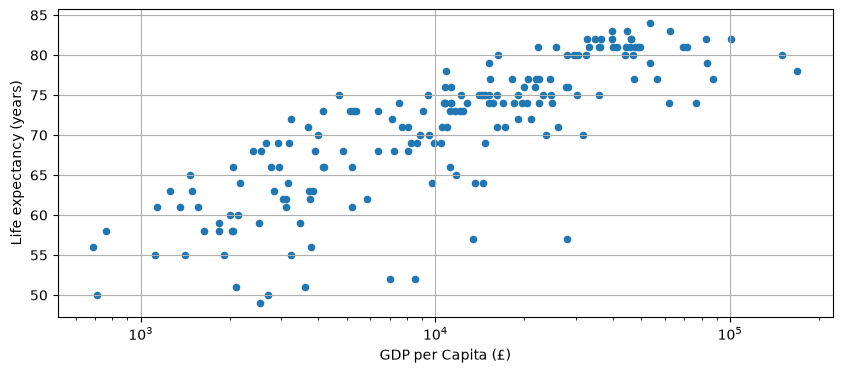

In [111]:
#Plot values
%matplotlib inline

gdpPcapVsLife.plot(x=GDP_PCAP, y=LIFE, kind='scatter', grid=True, logx=True, figsize=(10,4))
plt.show()

### Read and follow the below example analysis

## Project B: GDP and life expectancy

Richer countries can afford to invest more on healthcare, on work and road safety, and other measures that reduce mortality. On the other hand, richer countries may have less healthy lifestyles. Is there any relation between the wealth of a country and the life expectancy of its inhabitants?

The following analysis checks whether there is any correlation between the total gross domestic product (GDP) of a country in 2013 and the life expectancy of people born in that country in 2013.

## Getting the data

Two datasets of the World Bank are considered. One dataset, available at <http://data.worldbank.org/indicator/NY.GDP.MKTP.CD>, lists the GDP of the world's countries in current US dollars, for various years. The use of a common currency allows us to compare GDP values across countries. The other dataset, available at <http://data.worldbank.org/indicator/SP.DYN.LE00.IN>, lists the life expectancy of the world's countries. The datasets were downloaded as CSV files in March 2016.

In [ ]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import pandas as pd

# Load Data from cohort database (schema week08). See "Data Access (SQL).md".
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

YEAR = 2013
GDP_INDICATOR = 'NY.GDP.MKTP.CD'
gdpReset = run_query("SELECT * FROM week08.wb_gdp_2013")

LIFE_INDICATOR = 'SP.DYN.LE00.IN'
lifeReset = run_query("SELECT * FROM week08.wb_le_2013")
lifeReset.head()


## Cleaning the data

Inspecting the data with `head()` and `tail()` shows that:

1. the first 34 rows are aggregated data, for the Arab World, the Caribbean small states, and other country groups used by the World Bank;
- GDP and life expectancy values are missing for some countries.

The data is therefore cleaned by:
1. removing the first 34 rows;
- removing rows with unavailable values.

In [2]:
gdpCountries = gdpReset[34:].dropna()
lifeCountries = lifeReset[34:].dropna()

## Transforming the data

The World Bank reports GDP in US dollars and cents. To make the data easier to read, the GDP is converted to millions of British pounds (the author's local currency) with the following auxiliary functions, using the average 2013 dollar-to-pound conversion rate provided by <http://www.ukforex.co.uk/forex-tools/historical-rate-tools/yearly-average-rates>. 

In [3]:
def roundToMillions (value):
    return round(value / 1000000)

def usdToGBP (usd):
    return usd / 1.564768

GDP = 'GDP (£m)'
gdpCountries[GDP] = gdpCountries[GDP_INDICATOR].apply(usdToGBP).apply(roundToMillions)
gdpCountries.head()

,country,year,NY.GDP.MKTP.CD,GDP (£m)
34,Afghanistan,2013,2.045894e+10,13075
35,Albania,2013,1.278103e+10,8168
36,Algeria,2013,2.097035e+11,134016
38,Andorra,2013,3.249101e+09,2076
39,Angola,2013,1.383568e+11,88420


The unnecessary columns can be dropped.

In [4]:
COUNTRY = 'country'
headings = [COUNTRY, GDP]
gdpClean = gdpCountries[headings]
gdpClean.head()

,country,GDP (£m)
34,Afghanistan,13075
35,Albania,8168
36,Algeria,134016
38,Andorra,2076
39,Angola,88420


The World Bank reports the life expectancy with several decimal places. After rounding, the original column is discarded.

In [5]:
LIFE = 'Life expectancy (years)'
lifeCountries[LIFE] = lifeCountries[LIFE_INDICATOR].apply(round)
headings = [COUNTRY, LIFE]
lifeClean = lifeCountries[headings]
lifeClean.head()

,country,Life expectancy (years)
34,Afghanistan,60
35,Albania,78
36,Algeria,75
39,Angola,52
40,Antigua and Barbuda,76


## Combining the data

The tables are combined through an inner join on the common 'country' column. 

In [6]:
gdpVsLife = merge(gdpClean, lifeClean, on=COUNTRY, how='inner')
gdpVsLife.head()

,country,GDP (£m),Life expectancy (years)
0,Afghanistan,13075,60
1,Albania,8168,78
2,Algeria,134016,75
3,Angola,88420,52
4,Antigua and Barbuda,767,76


## Calculating the correlation

To measure if the life expectancy and the GDP grow together, the Spearman rank correlation coefficient is used. It is a number from -1 (perfect inverse rank correlation: if one indicator increases, the other decreases) to 1 (perfect direct rank correlation: if one indicator increases, so does the other), with 0 meaning there is no rank correlation. A perfect correlation doesn't imply any cause-effect relation between the two indicators. A p-value below 0.05 means the correlation is statistically significant.

In [7]:
from scipy.stats import spearmanr

gdpColumn = gdpVsLife[GDP]
lifeColumn = gdpVsLife[LIFE]
(correlation, pValue) = spearmanr(gdpColumn, lifeColumn)
print('The correlation is', correlation)
if pValue < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')

The correlation is 0.501023238967
It is statistically significant.


The value shows a direct correlation, i.e. richer countries tend to have longer life expectancy, but it is not very strong.

## Showing the data

Measures of correlation can be misleading, so it is best to see the overall picture with a scatterplot. The GDP axis uses a logarithmic scale to better display the vast range of GDP values, from a few million to several billion (million of million) pounds.

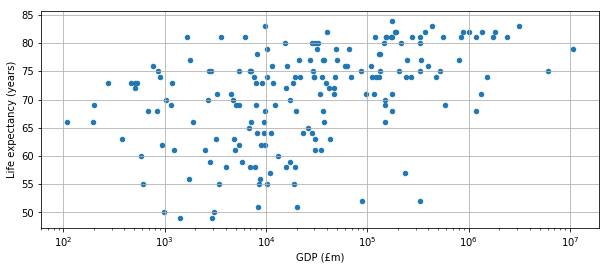

In [8]:
%matplotlib inline
gdpVsLife.plot(x=GDP, y=LIFE, kind='scatter', grid=True, logx=True, figsize=(10, 4))

The plot shows there is no clear correlation: there are rich countries with low life expectancy, poor countries with high expectancy, and countries with around 10 thousand (10<sup>4</sup>) million pounds GDP have almost the full range of values, from below 50 to over 80 years. Towards the lower and higher end of GDP, the variation diminishes. Above 40 thousand million pounds of GDP (3rd tick mark to the right of 10<sup>4</sup>), most countries have an expectancy of 70 years or more, whilst below that threshold most countries' life expectancy is below 70 years. 

Comparing the 10 poorest countries and the 10 countries with the lowest life expectancy shows that total GDP is a rather crude measure. The population size should be taken into account for a more precise definiton of what 'poor' and 'rich' means. Furthermore, looking at the countries below, droughts and internal conflicts may also play a role in life expectancy. 

In [9]:
# the 10 countries with lowest GDP
gdpVsLife.sort_values(GDP).head(10)

,country,GDP (£m),Life expectancy (years)
87,Kiribati,108,66
141,Sao Tome and Principe,195,66
111,"Micronesia, Fed. Sts.",202,69
168,Tonga,277,73
37,Comoros,383,63
157,St. Vincent and the Grenadines,461,73
140,Samoa,509,73
180,Vanuatu,512,72
65,Grenada,538,73
60,"Gambia, The",578,60


In [10]:
# the 10 countries with lowest life expectancy
gdpVsLife.sort_values(LIFE).head(10)

,country,GDP (£m),Life expectancy (years)
95,Lesotho,1418,49
160,Swaziland,2916,49
32,Central African Republic,983,50
146,Sierra Leone,3092,50
33,Chad,8276,51
41,Cote d'Ivoire,19998,51
3,Angola,88420,52
124,Nigeria,329100,52
30,Cameroon,18896,55
153,South Sudan,8473,55


## Conclusions

To sum up, there is no strong correlation between a country's wealth and the life expectancy of its inhabitants: there is often a wide variation of life expectancy for countries with similar GDP, countries with the lowest life expectancy are not the poorest countries, and countries with the highest expectancy are not the richest countries. Nevertheless there is some relationship, because the vast majority of countries with a life expectancy below 70 years is on the left half of the scatterplot.

Using the [NY.GDP.PCAP.PP.CD](http://data.worldbank.org/indicator/NY.GDP.PCAP.PP.CD) indicator, GDP per capita in current 'international dollars', would make for a better like-for-like comparison between countries, because it would take population and purchasing power into account. Using more specific data, like expediture on health, could also lead to a better analysis.

### Assessment - NOW IS YOUR TURN

**Create your own project**
Create a completely new project and choose another two of the
hundreds of World Bank indicators and see if there is any correlation between them. If
there is a choice of similar indicators, choose one that leads to meaningful
comparisons between countries.

Look at the results you obtained and take a few moments to assess how they differ.


## GOOD LUCK!

## Project: GDP Growth Vs Unemployment

This will analyze the correlation between a country's growth and its employment rate. It'll show whether a country's economic output affects job markets for the year 2016.

In [114]:
import warnings
warnings.simplefilter('ignore', FutureWarning)


In [ ]:
#GDP Growth VS Unemployment

#Defining constants to set the indicators 
GDP_GROWTH_INDICATOR = 'NY.GDP.MKTP.KD.ZG'
UNEMPLOYMENTINDICATOR = 'SL.UEM.TOTL.ZS'

#Getting the data
from pandas_datareader.wb import download
YEAR = 2016

growthWB = download(indicator=GDP_GROWTH_INDICATOR, country='all', start=YEAR, end=YEAR)
growthWB.head()

,,NY.GDP.MKTP.KD.ZG
country,year,
Africa Eastern and Southern,2016,2.292501
Africa Western and Central,2016,0.176172
Arab World,2016,3.572456
Caribbean small states,2016,-3.087398
Central Europe and the Baltics,2016,2.807249


In [119]:
unemploymentWB = download(indicator=UNEMPLOYMENTINDICATOR, country='all', start=YEAR, end=YEAR)
unemploymentWB.head()

,,SL.UEM.TOTL.ZS
country,year,
Africa Eastern and Southern,2016,7.074429
Africa Western and Central,2016,4.169102
Arab World,2016,10.861716
Caribbean small states,2016,8.528976
Central Europe and the Baltics,2016,6.476270


In [120]:
#Reset index for both data

growthReset = growthWB.reset_index()
unemploymentReset = unemploymentWB.reset_index()

In [128]:
#Drop missing values and remove regions for GDP growth

growthCountries = growthReset[49:].dropna()
growthCountries.head()

,country,year,NY.GDP.MKTP.KD.ZG
49,Afghanistan,2016,2.260314
50,Albania,2016,3.908936
51,Algeria,2016,3.900000
52,American Samoa,2016,-1.679389
53,Andorra,2016,3.709678


In [131]:
#Drop missing values and remove regions for Unemployment

unemploymentCountries = unemploymentReset[49:].dropna()
unemploymentCountries.head()

,country,year,SL.UEM.TOTL.ZS
49,Afghanistan,2016,10.116
50,Albania,2016,15.418
51,Algeria,2016,10.202
54,Angola,2016,16.572
56,Argentina,2016,8.088


In [132]:
#Dropping the year column for GDP growth

headings = ['country', GDP_GROWTH_INDICATOR]
growthCountries = growthCountries[headings]
growthCountries.head()

,country,NY.GDP.MKTP.KD.ZG
49,Afghanistan,2.260314
50,Albania,3.908936
51,Algeria,3.900000
52,American Samoa,-1.679389
53,Andorra,3.709678


In [133]:
#Dropping the year column for Unemployment

headings = ['country', UNEMPLOYMENTINDICATOR]
unemploymentCountries = unemploymentCountries[headings]
unemploymentCountries.head()

,country,SL.UEM.TOTL.ZS
49,Afghanistan,10.116
50,Albania,15.418
51,Algeria,10.202
54,Angola,16.572
56,Argentina,8.088


In [134]:
#Combining the datasets

gdpGrowthVsUnemployment = pd.merge(growthCountries, unemploymentCountries, on='country', how='inner')
gdpGrowthVsUnemployment.head()

,country,NY.GDP.MKTP.KD.ZG,SL.UEM.TOTL.ZS
0,Afghanistan,2.260314,10.116
1,Albania,3.908936,15.418
2,Algeria,3.900000,10.202
3,Angola,-0.233077,16.572
4,Argentina,-2.080328,8.088


In [135]:
#Renaming the columns

gdpGrowthVsUnemployment.rename(columns={'NY.GDP.MKTP.KD.ZG': 'GDP growth (annual %)', 'SL.UEM.TOTL.ZS': 'Unemployment'}, inplace=True)
gdpGrowthVsUnemployment.head()

,country,GDP growth (annual %),Unemployment
0,Afghanistan,2.260314,10.116
1,Albania,3.908936,15.418
2,Algeria,3.900000,10.202
3,Angola,-0.233077,16.572
4,Argentina,-2.080328,8.088


In [137]:
#Defining the column headings as constants

COUNTRY = 'country'
GDP_GROWTH = 'GDP growth (annual %)'
UNEMPLOYMENT = 'Unemployment'

headings = [COUNTRY, GDP_GROWTH, UNEMPLOYMENT]
gdpGrowthVsUnemploymentClean = gdpGrowthVsUnemployment[headings]
gdpGrowthVsUnemploymentClean.head()

,country,GDP growth (annual %),Unemployment
0,Afghanistan,2.260314,10.116
1,Albania,3.908936,15.418
2,Algeria,3.900000,10.202
3,Angola,-0.233077,16.572
4,Argentina,-2.080328,8.088


In [138]:
#Checking correlation

from scipy.stats import spearmanr

gdpGrowthColumn = gdpGrowthVsUnemploymentClean[GDP_GROWTH]
unemploymentColumn = gdpGrowthVsUnemploymentClean[UNEMPLOYMENT]

(correlation, pValue) = spearmanr(gdpGrowthColumn, unemploymentColumn)
print('The correlation is', correlation)
if pValue < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')

The correlation is -0.2870743457281571
It is statistically significant.


- Which means that there is a weak negative relationship between the two indicators; GDP growth and unemployment.
- A weak correlation (r = -0.287) was observed between the two indicators suggesting that the relationship between these indicators may not be directly linear and move in opposite directions indicating that when the GDP growth goes up, unemployment tands to go down and vice versa.
- Other socio-economic variables could mediate the connection between them.

<Axes: xlabel='GDP growth (annual %)', ylabel='Unemployment'>

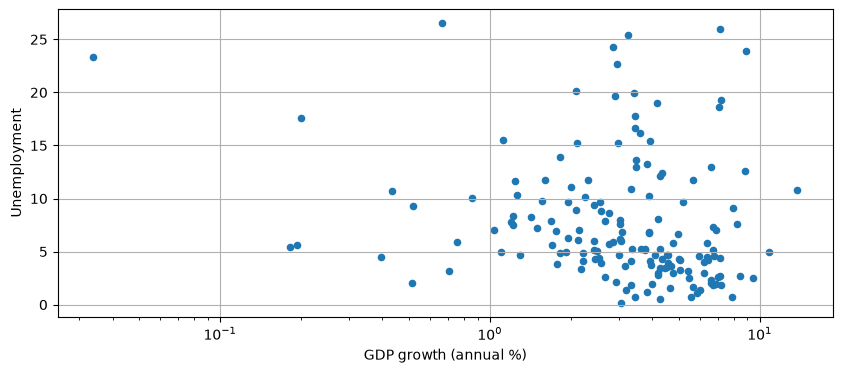

In [139]:
#Visualizing the relationship

%matplotlib inline

gdpGrowthVsUnemploymentClean.plot(x=GDP_GROWTH, y=UNEMPLOYMENT, kind='scatter', grid=True, logx=True, figsize=(10, 4))

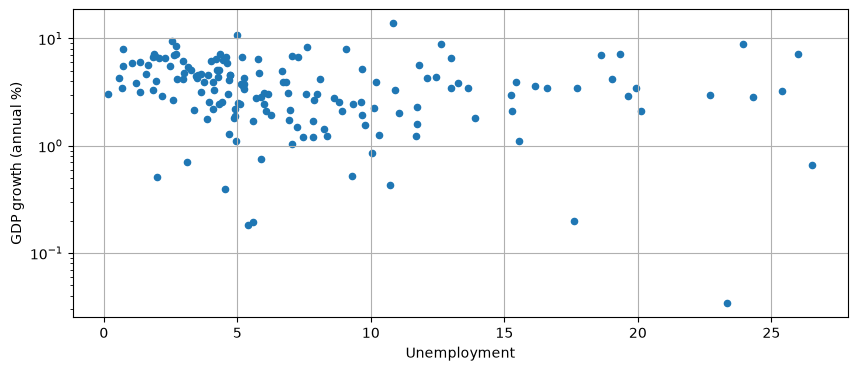

In [140]:
gdpGrowthVsUnemploymentClean.plot(x=UNEMPLOYMENT, y=GDP_GROWTH, kind='scatter', grid=True, logy=True, figsize=(10, 4))

plt.show()

In [ ]:
#10 countries with highest GDP growth

#Sort by GDP
sortedGdp = gdpGrowthVsUnemploymentClean.sort_values(by=GDP_GROWTH,ascending=False)

#The top 10 countries with highest GDP and low unemployment rate
sortedGDP = sortedGdp.head(10)
sortedGDP

,country,GDP growth (annual %),Unemployment
78,Iraq,13.787373,10.820
67,Guinea,10.820627,4.997
54,Ethiopia,9.433483,2.556
179,West Bank and Gaza,8.864619,23.939
77,"Iran, Islamic Rep.",8.815087,12.618
17,Bhutan,8.475943,2.707
75,India,8.256306,7.611
137,Samoa,7.983863,9.063
27,Cambodia,7.905501,0.716
20,Botswana,7.204425,19.328


In [145]:
#10 countries with lowest Unemployment

#Sort by Unemployment
sortedUnemployment = gdpGrowthVsUnemploymentClean.sort_values(by=UNEMPLOYMENT,ascending=False)

#The top 10 countries with highest unemployment rate and Lower GDP Growth
sortedUnemployment = sortedUnemployment.head(10)
sortedUnemployment

,country,GDP growth (annual %),Unemployment
148,South Africa,0.664552,26.536
46,Djibouti,7.123432,25.982
19,Bosnia and Herzegovina,3.242258,25.408
121,North Macedonia,2.848205,24.312
179,West Bank and Gaza,8.864619,23.939
64,Greece,-0.031795,23.514
114,Namibia,0.033794,23.352
53,Eswatini,2.949168,22.718
38,"Congo, Rep.",-8.685243,20.298
59,Gabon,2.091442,20.117


<!-- practice:start -->
---
## 🔁 SQL Practice

This week you cleaned messy weather data and combined World Bank tables in pandas. Now do the same jobs **in SQL**, straight from the raw tables: real analysts clean and combine data in the database before it ever reaches pandas.

**How it works**
1. Run the **practice setup** cell first (and again after restarting the kernel). It connects with your **read-only** account.
2. **SQL tasks:** write your query between the triple quotes and run the cell. `p.sql(...)` shows your result and
   says ✅ or ❌, and whether the **shape** (rows × columns) is right. Match the column order, sort order and rounding
   asked for (column *names* aren't checked).
3. Run `p.score()` at the end to see your practice score.

Refresh your memory with `Week-6 (Numpy & Pandas-1)/4-Intermediate SQL/Intermediate SQL.ipynb`.

In [ ]:
# --- practice setup: run this cell first (don't edit it) ---
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.practice import Practice, q

EXPECTED = {
 "s01": [
  [
   1,
   1
  ],
  "1ba5edf59854386be920ac9fd3e4a2af3bb6369bf2a1aef78dcdf908c96d70a9"
 ],
 "s02": [
  [
   5,
   3
  ],
  "19042d389224a7f56403ad9636ed581989f6639acadf45b15461f55cd6258da7"
 ],
 "s03": [
  [
   10,
   3
  ],
  "e3e296058facb3595b46ac98fb75d445a82240fc775f3188d029eabc5a362ddb"
 ],
 "s04": [
  [
   1,
   1
  ],
  "ba4a24ee999caa9e01607eb78856b7212bcce521b0f6fd42d8aa90541c10382d"
 ],
 "s05": [
  [
   1,
   2
  ],
  "8153d8bbbc1b43b88ce7e4ea0c99a4ac07f4b19e0f62a9a1e04df3271f2ad3df"
 ]
}   # fingerprints only: the answers are not stored here
TITLES = {
 "s01": "Cleaning a messy column",
 "s02": "Dates: a date range",
 "s03": "Combining tables (JOIN)",
 "s04": "What gets lost in a join?",
 "s05": "Window: the driest summer week"
}
p = Practice(EXPECTED, TITLES)
print(f"Practice ready: {len(TITLES)} tasks. Connected as:", q("SELECT CURRENT_USER AS u").u[0])

### SQL Task 1 · Cleaning a messy column

`week07.london_2014` is the **raw** export: the last column is literally named `WindDirDegrees<br />` and every
value ends in `<br />` (e.g. `'186<br />'`). Clean it **in SQL**: remove the `<br />`, convert to an integer, and
count the days when the wind direction was **greater than 350 degrees**.

**Return:** one row, one column (`days_over_350`).
💡 `REPLACE(...)`, `TRY_CAST(... AS int)`, and bracket-quote the odd column name: `[WindDirDegrees<br />]`.

In [ ]:
SQL_01 = """

"""
p.sql("s01", SQL_01)

### SQL Task 2 · Dates: a date range

`GMT` is stored as **text** like `'2014-1-1'`. Convert it to a real date and return London's weather for
**8–12 December 2014** (inclusive).

**Return:** `day` (a date), `Max TemperatureC`, `Min TemperatureC`, sorted by `day`.
💡 `TRY_CONVERT(date, GMT)` and `BETWEEN`.

In [ ]:
SQL_02 = """

"""
p.sql("s02", SQL_02)

### SQL Task 3 · Combining tables (JOIN)

Join `week08.wb_gdp_2013` and `week08.wb_le_2013` on `country`. Among entries with GDP **below 10 billion USD**
and a known life expectancy, return the **10 with the highest life expectancy**.

**Return:** `country`, `gdp_bn_usd` (GDP in billions, **rounded to 2 dp**), `life_expectancy` (**rounded to 1 dp**),
sorted by life expectancy (highest first), then `country` (A→Z) for ties.

In [ ]:
SQL_03 = """

"""
p.sql("s03", SQL_03)

### SQL Task 4 · What gets lost in a join?

In the lesson, `dropna()` removed rows before the merge. Count what would be lost: how many rows of
`week08.wb_gdp_2013` have **no usable match**, meaning either GDP is NULL, or the life-expectancy value for that
country is NULL (or missing)?

**Return:** one row, one column (`rows_lost`).
💡 `LEFT JOIN` and test for NULLs on both sides.

In [ ]:
SQL_04 = """

"""
p.sql("s04", SQL_04)

### SQL Task 5 · Window: the driest summer week

For the **Holiday weather** project: using London's **summer** (June, July, August 2014), find the **7-day
period with the least total rain**. A period is identified by its **start date** (that day + the next 6 days,
all inside the summer). If several periods tie, take the earliest.

**Return:** one row: `start_day` (a date), `rain_mm_7d` (**rounded to 2 dp**).
💡 `SUM(Precipitationmm) OVER (ORDER BY day ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING)` in a CTE, and only keep
start days whose window has a full 7 days.

In [ ]:
SQL_05 = """

"""
p.sql("s05", SQL_05)

### Practice score
Run this when you're done.

In [ ]:
p.score()

<!-- practice:end -->

---
## 📰 Article Link

Write a **detailed article** about this week's work. It should cover:

- **What you learnt:** the key concepts, tools and techniques from this week.
- **What you solved:** the tasks and projects you worked on, and how you approached them.
- **Challenges you faced:** what was hard, confusing or didn't work at first.
- **How you overcame them:** what you tried, what finally worked, and what you'd do differently.
- **Anything else you want to share:** insights, results, visuals, or advice for others learning this.

Publish it, then paste the article's **URL** in the empty cell below (double-click the cell to edit it).